In [1]:
import pandas as pd
import numpy as np
import seaborn as sns                       #visualisation
import matplotlib.pyplot as plt             #visualisation
 
df = pd.read_csv("train_storming_round.csv")

df.head(5)

,row_id,agent_code,agent_age,agent_join_month,first_policy_sold_month,year_month,unique_proposals_last_7_days,unique_proposals_last_15_days,unique_proposals_last_21_days,unique_proposal,...,unique_quotations,unique_customers_last_7_days,unique_customers_last_15_days,unique_customers_last_21_days,unique_customers,new_policy_count,ANBP_value,net_income,number_of_policy_holders,number_of_cash_payment_policies
0,1,455ca878,45,2/1/2021,9/1/2023,1/1/2023,3,6,2,12,...,9,3,4,8,15,0,0,93313,30,162
1,2,c823ce77,48,4/1/2022,2/1/2024,1/1/2023,1,4,12,21,...,14,4,3,10,17,25,1071450,164804,0,175
2,3,62154055,53,5/1/2020,9/1/2023,1/1/2023,3,5,5,17,...,14,3,7,11,21,26,1601210,426690,84,78
3,4,c58bfa6e,44,7/1/2019,3/1/2022,1/1/2023,1,0,12,17,...,11,2,2,9,13,18,283230,47793,39,144
4,5,b1e5f770,20,9/1/2020,2/1/2023,1/1/2023,0,6,10,17,...,13,3,10,6,19,20,1957680,562239,19,40


In [2]:
df.tail(5)

,row_id,agent_code,agent_age,agent_join_month,first_policy_sold_month,year_month,unique_proposals_last_7_days,unique_proposals_last_15_days,unique_proposals_last_21_days,unique_proposal,...,unique_quotations,unique_customers_last_7_days,unique_customers_last_15_days,unique_customers_last_21_days,unique_customers,new_policy_count,ANBP_value,net_income,number_of_policy_holders,number_of_cash_payment_policies
15303,15304,d3b44e44,43,4/1/2019,10/1/2023,8/1/2024,1,6,6,17,...,10,3,4,11,18,25,2473900,404980,18,100
15304,15305,0b1d7054,28,9/1/2022,3/1/2024,8/1/2024,1,5,3,13,...,14,4,3,11,18,15,922050,198187,18,120
15305,15306,51321fa2,45,1/1/2021,4/1/2024,8/1/2024,0,6,17,26,...,22,6,7,6,19,30,645330,133263,57,270
15306,15307,dd4a0d2d,25,12/1/2021,12/1/2023,8/1/2024,0,4,6,14,...,13,6,3,6,15,0,0,32546,30,171
15307,15308,393f3bf6,53,1/1/2023,2/1/2024,8/1/2024,1,4,7,16,...,9,3,8,1,12,19,1726568,295565,36,0


### **Part 1 - Key metrics and distributions**

In [3]:
df.dtypes

row_id                              int64
agent_code                         object
agent_age                           int64
agent_join_month                   object
first_policy_sold_month            object
year_month                         object
unique_proposals_last_7_days        int64
unique_proposals_last_15_days       int64
unique_proposals_last_21_days       int64
unique_proposal                     int64
unique_quotations_last_7_days       int64
unique_quotations_last_15_days      int64
unique_quotations_last_21_days      int64
unique_quotations                   int64
unique_customers_last_7_days        int64
unique_customers_last_15_days       int64
unique_customers_last_21_days       int64
unique_customers                    int64
new_policy_count                    int64
ANBP_value                          int64
net_income                          int64
number_of_policy_holders            int64
number_of_cash_payment_policies     int64
dtype: object

**Droping irrelevant columns**

In [4]:
df.drop(['row_id','agent_code'],axis=1,inplace=True)
df.head(5)

,agent_age,agent_join_month,first_policy_sold_month,year_month,unique_proposals_last_7_days,unique_proposals_last_15_days,unique_proposals_last_21_days,unique_proposal,unique_quotations_last_7_days,unique_quotations_last_15_days,...,unique_quotations,unique_customers_last_7_days,unique_customers_last_15_days,unique_customers_last_21_days,unique_customers,new_policy_count,ANBP_value,net_income,number_of_policy_holders,number_of_cash_payment_policies
0,45,2/1/2021,9/1/2023,1/1/2023,3,6,2,12,3,0,...,9,3,4,8,15,0,0,93313,30,162
1,48,4/1/2022,2/1/2024,1/1/2023,1,4,12,21,3,1,...,14,4,3,10,17,25,1071450,164804,0,175
2,53,5/1/2020,9/1/2023,1/1/2023,3,5,5,17,1,6,...,14,3,7,11,21,26,1601210,426690,84,78
3,44,7/1/2019,3/1/2022,1/1/2023,1,0,12,17,1,1,...,11,2,2,9,13,18,283230,47793,39,144
4,20,9/1/2020,2/1/2023,1/1/2023,0,6,10,17,3,6,...,13,3,10,6,19,20,1957680,562239,19,40


In [5]:
df.count()

agent_age                          15308
agent_join_month                   15308
first_policy_sold_month            15308
year_month                         15308
unique_proposals_last_7_days       15308
unique_proposals_last_15_days      15308
unique_proposals_last_21_days      15308
unique_proposal                    15308
unique_quotations_last_7_days      15308
unique_quotations_last_15_days     15308
unique_quotations_last_21_days     15308
unique_quotations                  15308
unique_customers_last_7_days       15308
unique_customers_last_15_days      15308
unique_customers_last_21_days      15308
unique_customers                   15308
new_policy_count                   15308
ANBP_value                         15308
net_income                         15308
number_of_policy_holders           15308
number_of_cash_payment_policies    15308
dtype: int64

**----Calculating the mean,standard deviation,minimum and the interquartile values for each numeric column----**

In [6]:
summary = df.describe().T  # Transpose to make it easier to read
summary['range'] = summary['max'] - summary['min']
summary['iqr'] = summary['75%'] - summary['25%']
summary_formatted = summary.round(2)  # rounds to 2 decimal places
summary_formatted

,count,mean,std,min,25%,50%,75%,max,range,iqr
agent_age,15308.0,40.59,11.69,20.0,31.00,41.0,51.00,60.0,40.0,20.00
unique_proposals_last_7_days,15308.0,1.49,1.12,0.0,0.00,1.0,2.00,3.0,3.0,2.00
unique_proposals_last_15_days,15308.0,2.99,2.00,0.0,1.00,3.0,5.00,6.0,6.0,4.00
unique_proposals_last_21_days,15308.0,10.05,6.04,0.0,5.00,10.0,15.00,20.0,20.0,10.00
unique_proposal,15308.0,17.52,6.62,1.0,12.00,17.0,23.00,34.0,33.0,11.00
unique_quotations_last_7_days,15308.0,1.99,1.42,0.0,1.00,2.0,3.00,4.0,4.0,2.00
unique_quotations_last_15_days,15308.0,3.00,2.00,0.0,1.00,3.0,5.00,6.0,6.0,4.00
unique_quotations_last_21_days,15308.0,4.47,2.88,0.0,2.00,4.0,7.00,9.0,9.0,5.00
unique_quotations,15308.0,13.92,4.66,1.0,11.00,14.0,17.00,32.0,31.0,6.00
unique_customers_last_7_days,15308.0,3.00,1.64,0.0,2.00,3.0,4.00,6.0,6.0,2.00


#### **---Identifying outliers---**
-----Here we use box plots to find outliers in the dataset for each numerical column

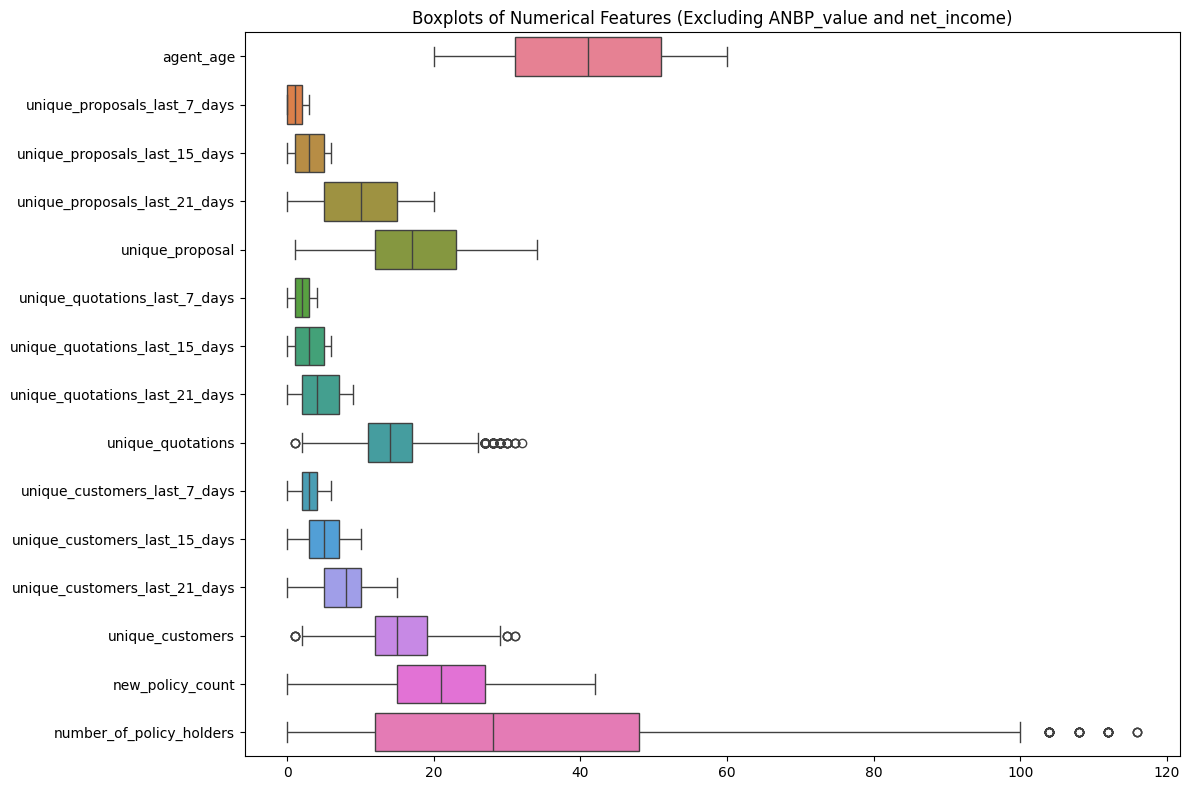

In [7]:
# Exclude 'ANBP_value' and 'net_income' columns from the DataFrame
df_filtered = df.drop(columns=['ANBP_value', 'net_income','number_of_cash_payment_policies'])

# Plotting boxplots for all other numerical columns
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_filtered.select_dtypes(include='number'), orient='h')
plt.title('Boxplots of Numerical Features (Excluding ANBP_value and net_income)')
plt.tight_layout()
plt.show()

<Axes: xlabel='ANBP_value'>

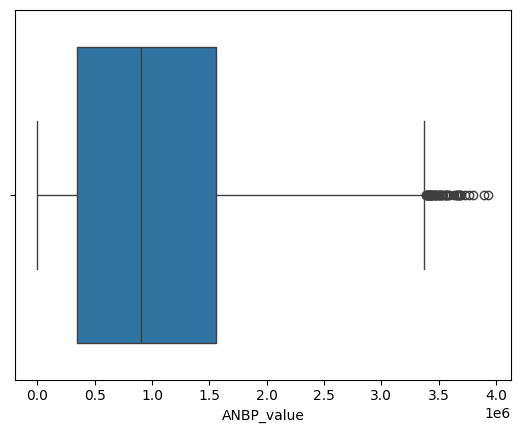

In [8]:
sns.boxplot(x=df['ANBP_value'])

<Axes: xlabel='net_income'>

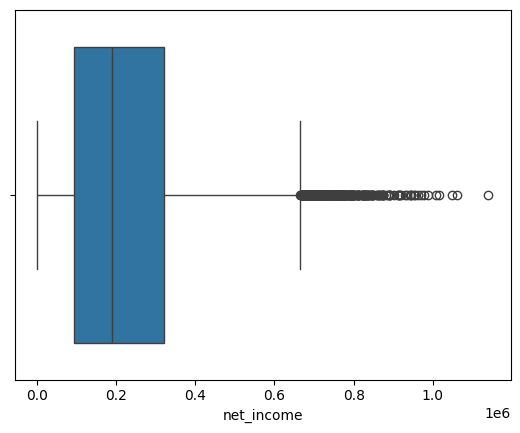

In [9]:
sns.boxplot(x=df['net_income'])

##### **----Deriving the target column using new_policy_count**

In [10]:
df['target'] = (df['new_policy_count'] > 0).astype(int)

**Plotting a graph to find the distributions of 1s and 0s in the target column**

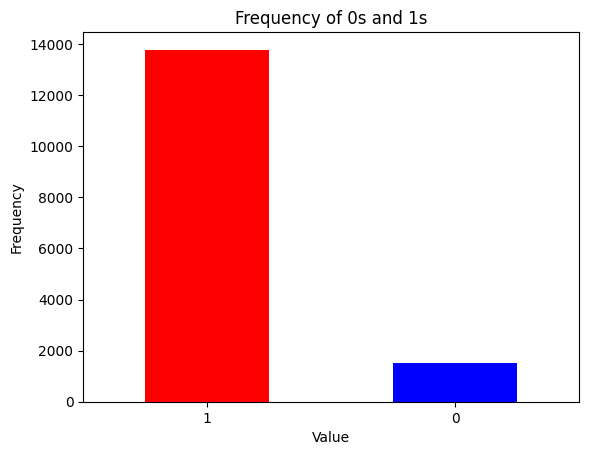

In [11]:
df['target'].value_counts().plot(kind='bar', color=['red', 'blue'])
plt.title('Frequency of 0s and 1s')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.xticks(rotation=0)
plt.show()

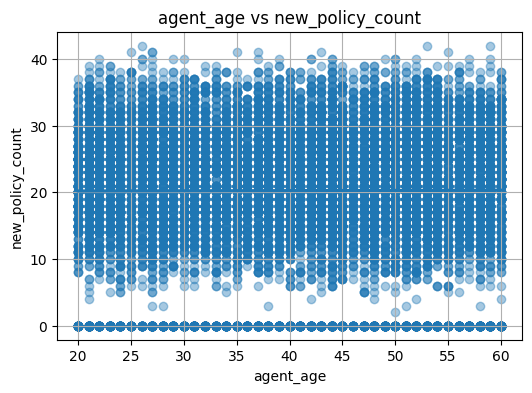

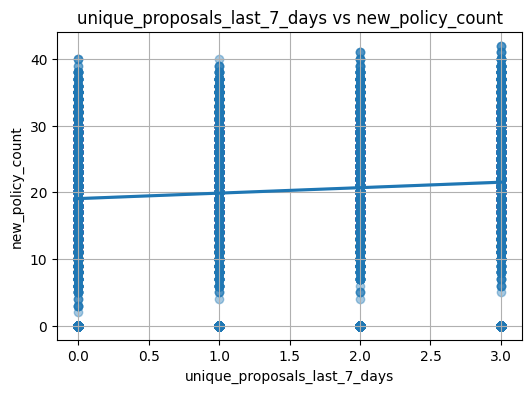

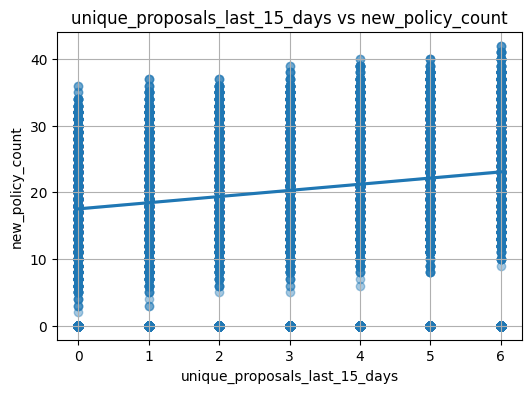

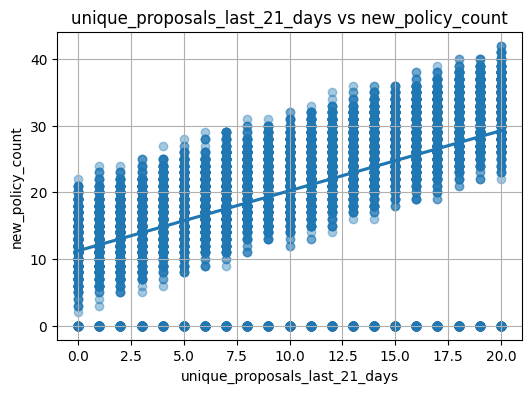

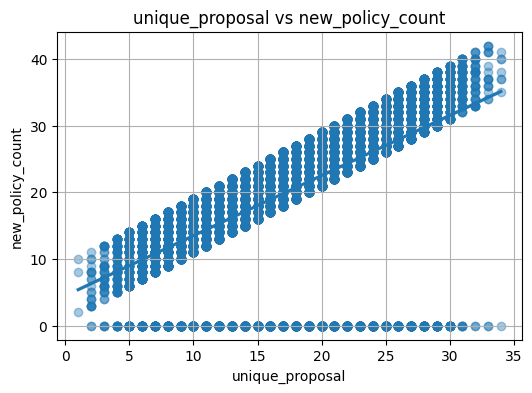

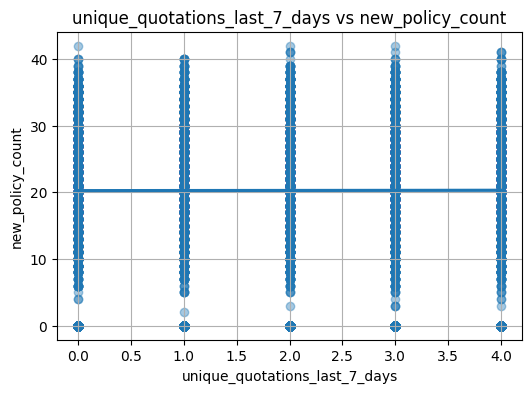

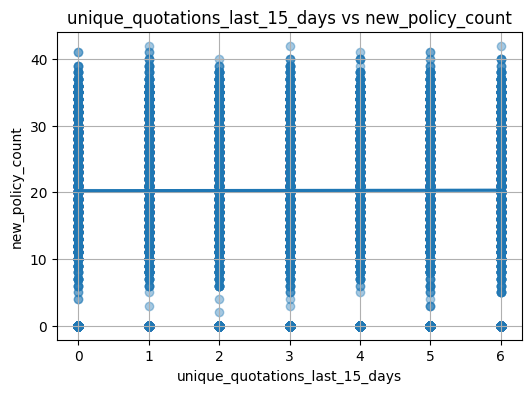

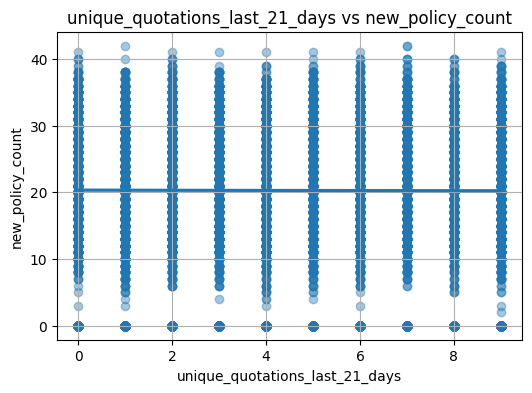

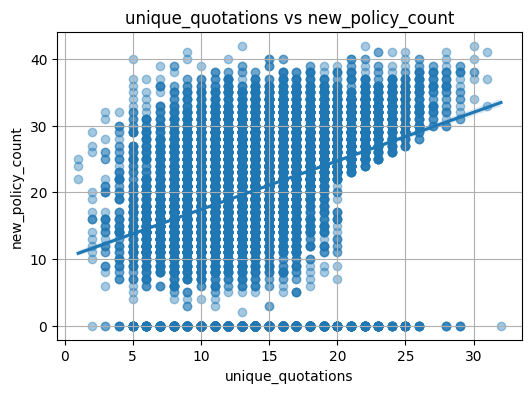

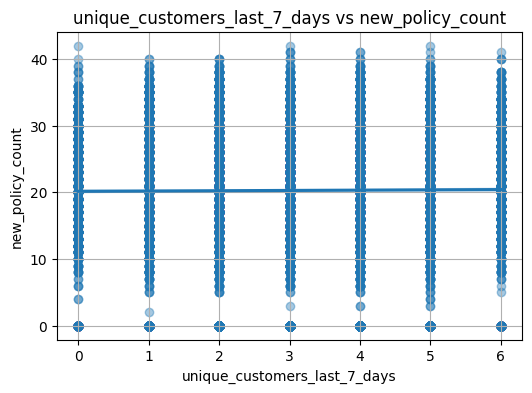

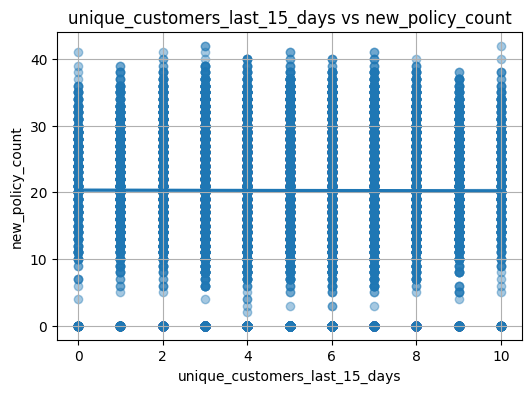

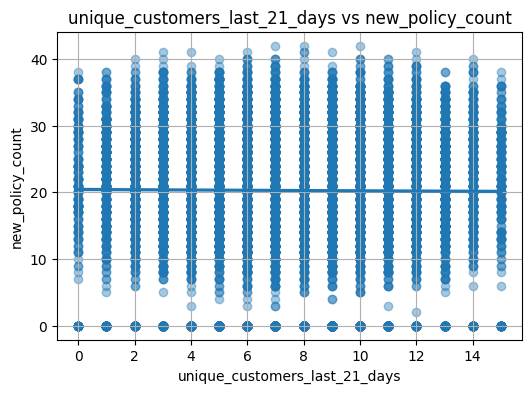

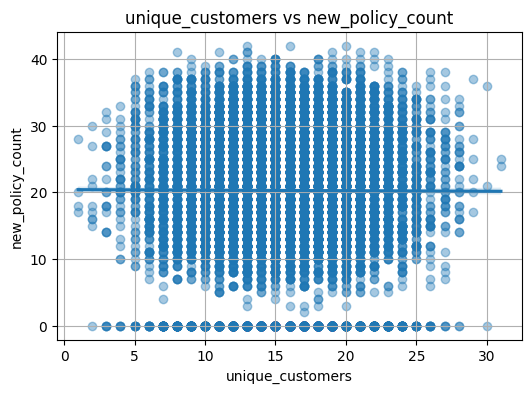

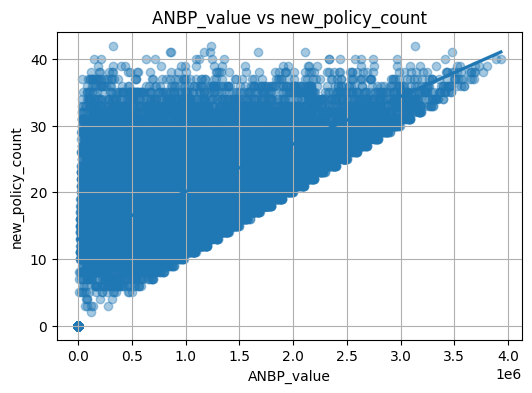

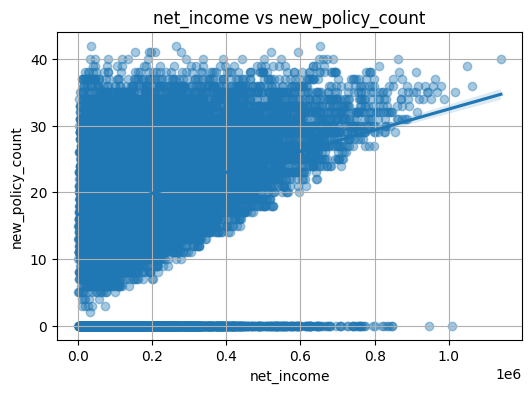

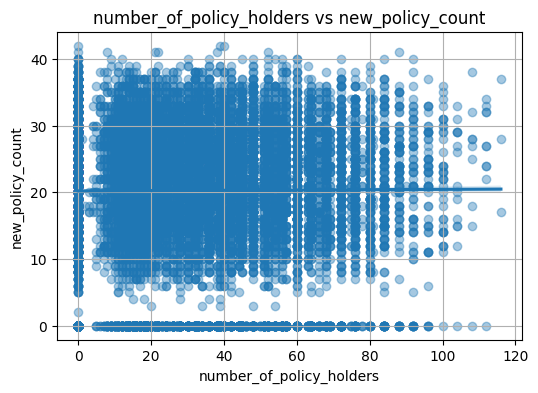

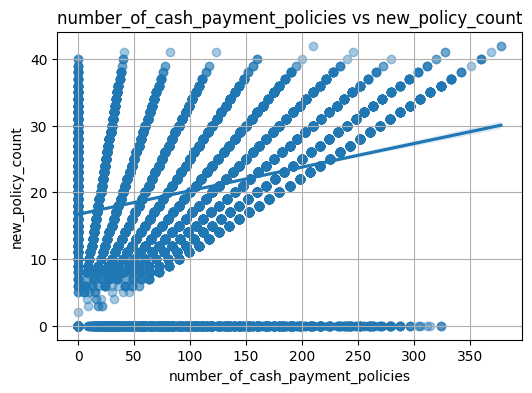

In [12]:
numeric_features = df.select_dtypes(include='number').columns.tolist()

# Optionally, remove the target column
target = 'new_policy_count'
numeric_features = [col for col in numeric_features if (col != "target" and col != "new_policy_count")]

for feature in numeric_features:
    plt.figure(figsize=(6, 4))
    sns.regplot(data=df, x=feature, y=target, scatter_kws={'alpha':0.4})
    plt.title(f'{feature} vs {target}')
    plt.grid(True)
    plt.show()


In [13]:
import pandas as pd
from scipy.stats import pearsonr

# target: 1 if the agent sold at least one new policy that month
numeric_columns = df.select_dtypes(include=['number']).columns

# Dictionary to store correlations
correlations = {}

# Loop through numeric columns and calculate Pearson's Correlation
for col in numeric_columns:
    correlation, p_value = pearsonr(df['new_policy_count'], df[col])
    correlations[col] = correlation

# Display the correlations
correlations

{'agent_age': 0.003663488251658566,
 'unique_proposals_last_7_days': 0.09618422973920115,
 'unique_proposals_last_15_days': 0.19393430999856243,
 'unique_proposals_last_21_days': 0.569787919743747,
 'unique_proposal': 0.6249037418434805,
 'unique_quotations_last_7_days': 0.0018100247245810344,
 'unique_quotations_last_15_days': 0.0022145502556924507,
 'unique_quotations_last_21_days': -0.003038311114634878,
 'unique_quotations': 0.35649537707369894,
 'unique_customers_last_7_days': 0.007515184373395021,
 'unique_customers_last_15_days': -0.002233340896493729,
 'unique_customers_last_21_days': -0.007093615693676733,
 'unique_customers': -0.0038958014736712844,
 'new_policy_count': 1.0,
 'ANBP_value': 0.6028118328745933,
 'net_income': 0.28789928004833804,
 'number_of_policy_holders': 0.006099286913045111,
 'number_of_cash_payment_policies': 0.2790409867575976,
 'target': 0.7079374461027566}

#### Feature Selection Insights from Scatterplots and Pearson Correlation

From the scatterplots (plotted against `new_policy_count`) and the computed Pearson correlation values, we can observe that several features show a notable relationship with the target variable. These features demonstrate trends or linear associations that may contribute significantly to predicting `new_policy_count`.

##### Key Features Identified:
- `unique_proposals_last_21_days`
- `unique_proposal`
- `ANBP_value`
- `unique_quotations`
- `net_income`

These features should be considered strong candidates for inclusion in our predictive modeling pipeline, given their visible patterns and meaningful Pearson correlation scores with the target.


### **Part 2 - How do sales patterns vary by month**

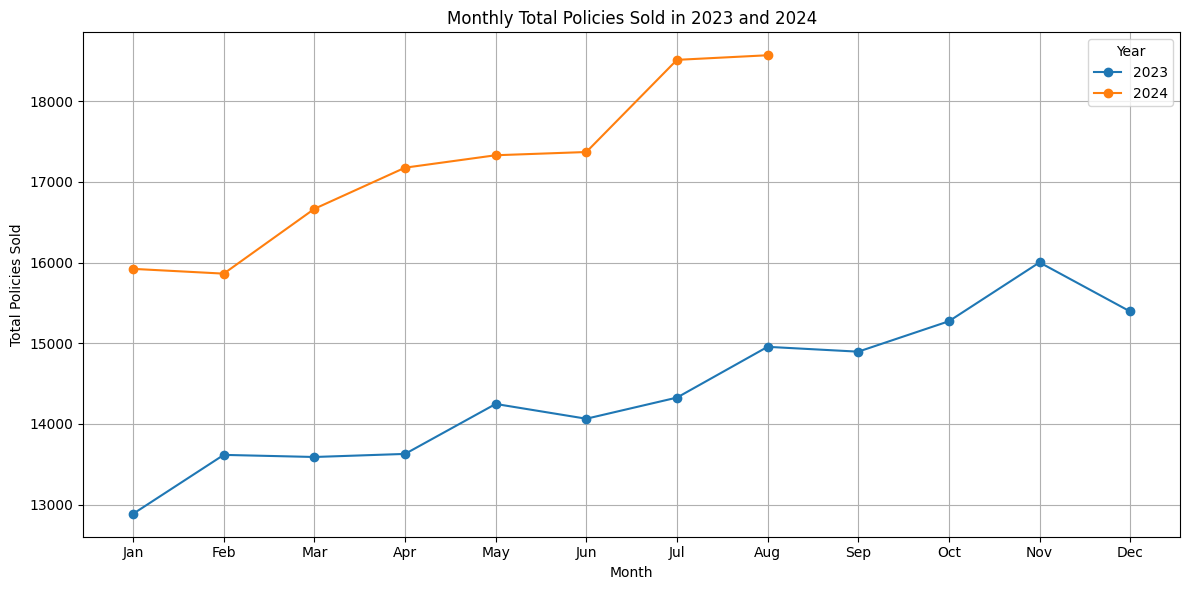

In [14]:
df['year_month'] = pd.to_datetime(df['year_month'], format="%m/%d/%Y")

# Extract year and month
df['year'] = df['year_month'].dt.year
df['month'] = df['year_month'].dt.month

# Filter for 2023 and 2024
df_filtered = df[df['year'].isin([2023, 2024])]

# Group by year and month, and sum policies sold
monthly_sales = df_filtered.groupby(['year', 'month'])['new_policy_count'].sum().reset_index()

# Pivot the data for line plot
pivot_table = monthly_sales.pivot(index='month', columns='year', values='new_policy_count')

# Plot the line chart
plt.figure(figsize=(12, 6))
for year in pivot_table.columns:
    plt.plot(pivot_table.index, pivot_table[year], marker='o', label=f"{year}")

plt.title("Monthly Total Policies Sold in 2023 and 2024")
plt.xlabel("Month")
plt.ylabel("Total Policies Sold")
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.legend(title="Year")
plt.grid(True)
plt.tight_layout()
plt.show()

####  Monthly Policy Sales Analysis (2023 vs 2024)

The line chart compares the total number of policies sold each month in 2023 and 2024. A clear upward trend is observed in both years, with 2024 consistently outperforming 2023 in every month for which data is available.

####  2023 Sales Trends:
- Sales started at around **12,900** in January and generally increased over the year.
- A **steady climb** can be seen from February through November, peaking at **16,000 policies** in November.
- A slight **drop is noticeable in December**, where sales fell back to around **15,400**—possibly due to seasonal slowdown or holiday effects.

####  2024 Sales Trends:
- Sales began strong at **15,900** in January and rose steadily each month.
- There’s a **significant spike between June and July**, jumping from ~17,400 to **18,500**.
- This peak continued into August, with sales reaching the year’s high of **18,600**.
- The growth appears **more consistent and aggressive** than in 2023, with no noticeable declines in the available data range.

---

####  Key Observations:
- **No unexpected drops** in 2024; the growth trajectory is stable and upward.
- **December 2023** is the only month showing a **minor decline**, potentially due to end-of-year factors.
- The **mid-year acceleration** in 2024 (June–August) suggests a possible campaign, market push, or seasonal demand surge.


### **Part 3 - How do all numerical features interact simultaneously**

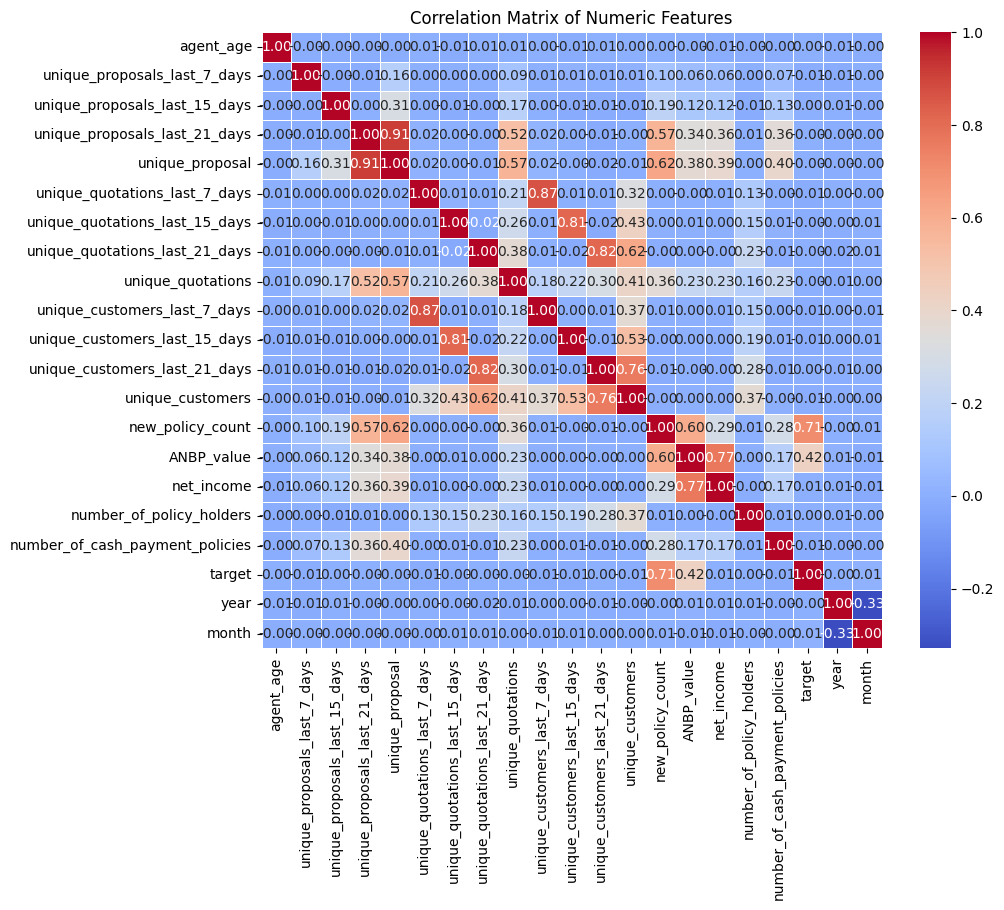

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# df: one row per agent per month
numeric_df = df.select_dtypes(include='number')  # Select numeric columns

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Numeric Features")
plt.show()


#### Correlation Matrix Insights

Based on the correlation heatmap, here are the key insights derived from the numerical features:

---

#### 1. Highly Correlated Feature Clusters

Several groups of features exhibit strong **positive correlations**, indicating they likely represent the same underlying information and could be redundant:

##### Proposals
- `unique_proposals_last_7/15/21_days` show high correlation with `unique_proposal`  
  **(Correlation ~0.57–0.91)**  
  These are expected to be subsets of the total proposal count, so the strong correlation is natural and highlights redundancy.

##### Quotations
- `unique_quotations_last_7/15/21_days` are strongly correlated with `unique_quotations`  
  **(Correlation ~0.82–0.88)**  
  Similar to the proposals, these are just segmented views of the same feature across different time windows.

##### Customers
- `unique_customers_last_7/15/21_days` are also strongly correlated with `unique_customers`  
  **(Correlation ~0.62–0.76)**  
  Again, these time-based features are subsets of the overall customer count.

##### Business Metrics
- `new_policy_count`, `ANBP_value`, and `net_income` show moderate correlations with:
  - `unique_customers`
  - `unique_proposals`
  **(Correlation ~0.28–0.71)**  
  These metrics likely follow the same business trend—more customers or proposals tend to drive policy count and revenue.


---

#### 2. Weak or No Correlation with Target

- The `target` variable shows **very weak correlation** with all other numerical features.  
  This indicates that **linear relationships** do not explain the target well, and more complex (nonlinear) models may be needed to capture useful patterns.

---

#### 3. Agent Age

- `agent_age` appears **uncorrelated** with all other features, including `target`.  
  - This suggests it may not contribute much predictive value on its own, though it might still be useful in combination with other features.

---

#### 4. Temporal Features

- `month` has a **mild correlation (~0.33)** with `target`, suggesting some **seasonal trends** could be present.
- `year` shows **negligible correlation**, likely due to limited variation (e.g., data collected within a single year).

---

### Summary

- Time-windowed features are heavily correlated with their cumulative counterparts—consider aggregating or dropping some.
- Nonlinear models are likely better suited for predicting the target.
- Look into feature interactions or temporal patterns (e.g., seasonal effects) for additional insight.


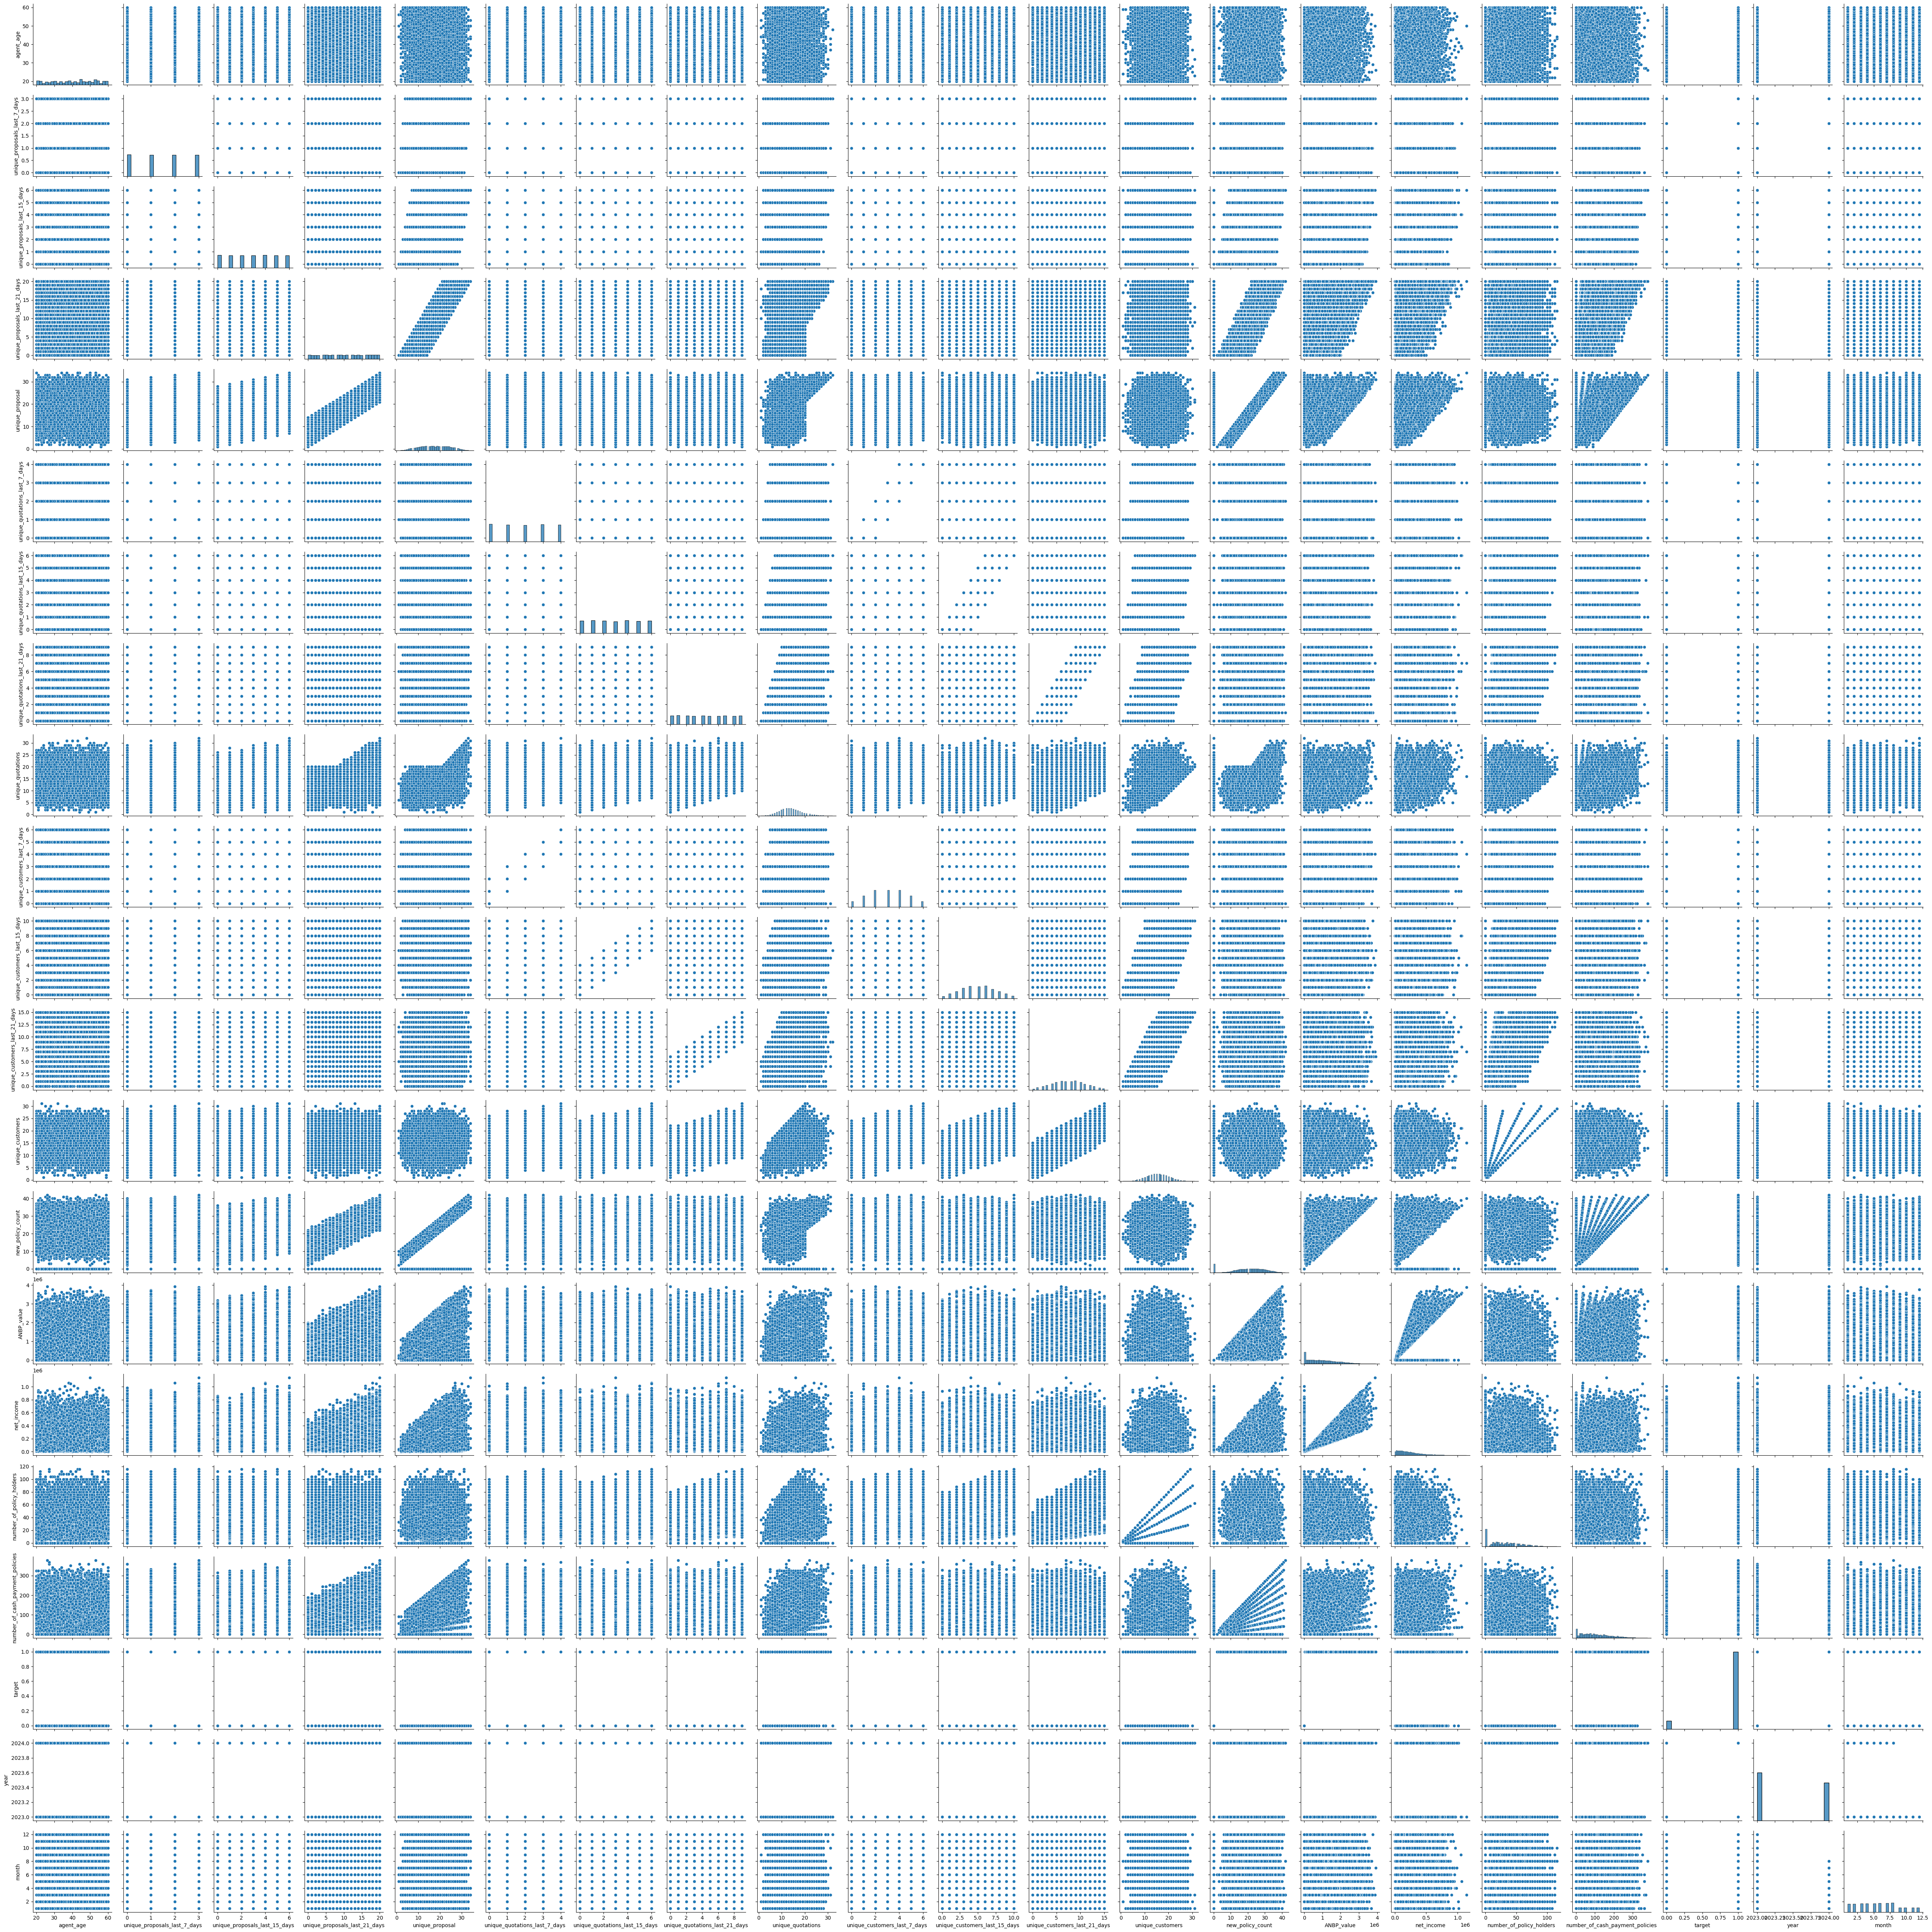

In [16]:
import seaborn as sns

# Plot pairplot
sns.pairplot(numeric_df)


####  Pairplot vs Correlation Matrix — Comparative Insights

The pairplot provides a visual representation of how numerical features interact, complementing the correlation matrix's numerical summary. Here's what we observed:

---

###  1. Strong Linear Relationships (Confirmed)

From the correlation matrix, we identified:
- High correlations among:
  - `unique_proposals_*` features
  - `unique_quotations_*` features
  - `unique_customers_*` features

 **Pairplot confirms** these relationships — clear **diagonal lines** or **dense linear clusters** are visible between these variables.  
These patterns visually validate the redundancy suggested in the heatmap.

>  Redundant time-windowed features — consider dropping or aggregating.

---

###  2. Nonlinear or No Clear Relationships

The correlation matrix showed that:
- `target` had **low correlation** with almost all other features.

 The pairplot reinforces this — **no strong pattern** or shape is visible between `target` and other variables.  
→ This suggests that linear models will likely **struggle**, and **nonlinear models** (e.g., tree-based) are worth exploring.

---

###  3. Agent Age

From the correlation matrix:
- `agent_age` had **no strong correlations** with anything.

 In the pairplot, this is reflected in **scatterplots with no trend** or structure involving `agent_age`, reinforcing its limited standalone predictive value.

---

###  4. Temporal Features (`month`, `year`)

The heatmap showed:
- `month` had **weak-to-moderate** correlation with `target` (~0.33)
- `year` had **negligible** correlation

 **Pairplot view:**
- `month` shows **some mild patterns** with variables like `target` and `net_income`, possibly indicating **seasonality**
- `year` appears mostly **constant or categorical**, explaining its weak interaction.

---

###  Bonus Insights from Pairplot

- The **density** and **striped patterns** in some plots (e.g., `net_income`, `new_policy_count`) may suggest **discrete or capped values**.
- Some variables exhibit **nonlinear but structured relationships** (e.g., curves or clusters), which are **not captured by correlation coefficients** — a major advantage of pairplots.

---




### **Part 4 - How agents performance evolves with time**

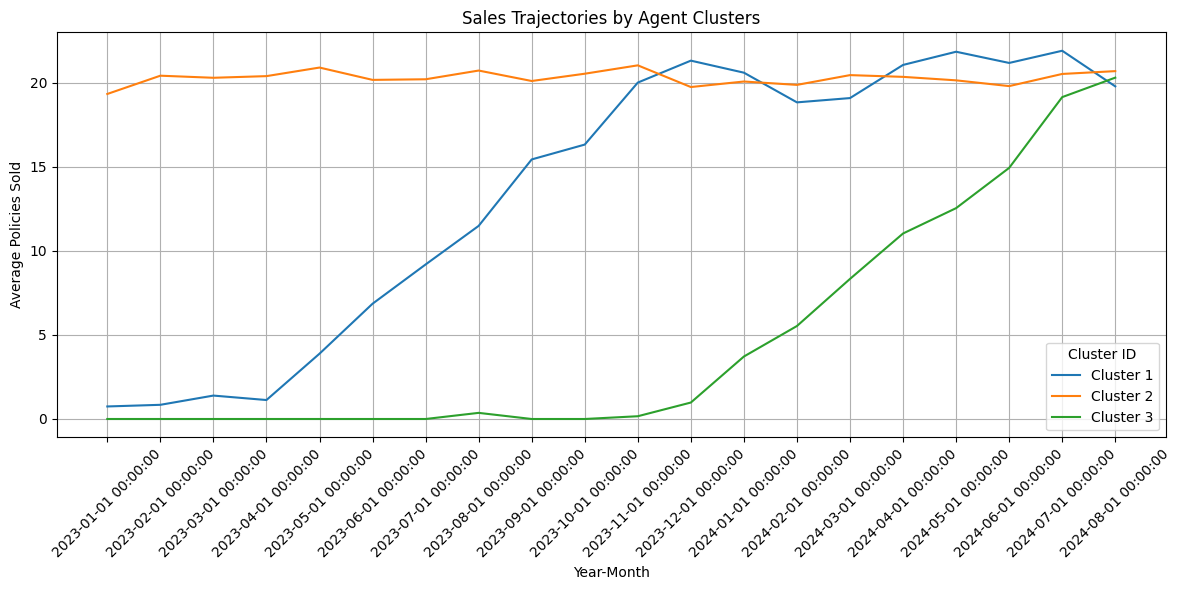

year_month  cluster
agent_id           
9bf2290b          0
cbb419aa          0
974da954          0
9716c60e          0
62d089a7          0
...             ...
64e42473          2
c21ae5a1          2
6643513a          2
deb74689          2
bda544ec          2

[905 rows x 1 columns]


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans



# Pivot the data to have agents as rows and months as columns
pivoted_data = df.pivot_table(index='agent_id', columns='year_month', values='new_policy_count', aggfunc='sum').fillna(0)

# Perform K-means clustering
n_clusters = 3  # high, medium and low performers
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
pivoted_data['cluster'] = kmeans.fit_predict(pivoted_data)

# Plotting the average sales trajectory of each cluster
plt.figure(figsize=(12, 6))

# Plot each cluster's average trajectory
for cluster in range(n_clusters):
    cluster_data = pivoted_data[pivoted_data['cluster'] == cluster].drop(columns=['cluster'])
    plt.plot(cluster_data.columns.astype(str), cluster_data.mean(axis=0), label=f'Cluster {cluster + 1}')

plt.title('Sales Trajectories by Agent Clusters')
plt.xlabel('Year-Month')
plt.ylabel('Average Policies Sold')
plt.legend(title="Cluster ID")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Optional: Show which agents belong to which clusters
print(pivoted_data[['cluster']].sort_values('cluster'))


#### Performance Analysis of Clusters

- **Cluster 1 (High Performers):**  
  Agents in Cluster 1 consistently performed well throughout the study period. They maintained a high level of performance with a stable average of policies sold, showing steady results over time.

- **Cluster 2 and Cluster 3 (Beginners):**  
  Both Cluster 2 and Cluster 3 consist of beginner agents with a significantly lower average of policies sold compared to Cluster 1. However, with time, both clusters managed to improve and eventually reached the performance level of Cluster 1.

- **Cluster 3 - Slower Progress:**  
  While Cluster 2 agents were able to catch up with the performance of Cluster 1 relatively quickly, Cluster 3 agents took considerably longer to reach the same level of success.
